In [461]:
# these are usual imports in a classic ML pipeline for Regression
# pip install numpy
# pip install pandas
# pip install seaborn
# pip install scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

### STEP 1 - Load the data

In [462]:
# load the data but before we remove the categories and we do it before reading it,
#  because they are to heavy and the dataset is already long
REMOVE = ["description", "image_url", "url", "region_url", "id", "county",
          "VIN", "size", "region", "model", "posting_date", "lat", "long"]
df = pd.read_csv("vehicles.csv", usecols=lambda col: col not in REMOVE)

# we remove duplicate data
df = df.drop_duplicates()

# let's see the first 5 rows
# there's only 30 rows in total, so this is only a demonstration
# on how to use scikit-learn, the dataset itself is not very useful
df

,price,year,manufacturer,condition,cylinders,fuel,odometer,title_status,transmission,drive,type,paint_color,state
0,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az
1,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar
2,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl
3,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ma
4,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nc
...,...,...,...,...,...,...,...,...,...,...,...,...,...
426875,23590,2019.0,nissan,good,6 cylinders,gas,32226.0,clean,other,fwd,sedan,NaN,wy
426876,30590,2020.0,volvo,good,NaN,gas,12029.0,clean,other,fwd,sedan,red,wy
426877,34990,2020.0,cadillac,good,NaN,diesel,4174.0,clean,other,NaN,hatchback,white,wy
426878,28990,2018.0,lexus,good,6 cylinders,gas,30112.0,clean,other,fwd,sedan,silver,wy


In [463]:
#Lets check which columns have less than 3% of NaN and we delete that rows
(df.isna().mean() * 100).round(1)


price            0.0
year             0.3
manufacturer     4.4
condition       37.7
cylinders       38.8
fuel             0.6
odometer         0.9
title_status     1.6
transmission     0.5
drive           29.5
type            23.0
paint_color     29.1
state            0.0
dtype: float64

### STEP 2: Basic data checks, duplicates or missing values (NaN)?

In [464]:
# Delete rows that have less than 4% of NaN
df = df.dropna(subset=['year', 'manufacturer', 'fuel', 'odometer',
                       'title_status', 'transmission'])

# rows with many NaN fill with unknown
cols = ['condition', 'cylinders', 'drive', 'type', 'paint_color']
df[cols] = df[cols].fillna('Unknown')

# remove unrealistic prices (0 or absurdly high)
df = df[(df['price'] > 500) & (df['price'] < 100000)]

# remove classic cars (pre-1995) and unrealistic odometer values (400000 milles == 644.000 km)
df = df[(df['year'] >= 1995) & (df['odometer'] < 400000)]

df.isna().sum()

C:\Users\pablo\AppData\Local\Temp\ipykernel_34044\1948816109.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[cols] = df[cols].fillna('Unknown')


price           0
year            0
manufacturer    0
condition       0
cylinders       0
fuel            0
odometer        0
title_status    0
transmission    0
drive           0
type            0
paint_color     0
state           0
dtype: int64

In [465]:
int(df.duplicated().sum())

0

In [466]:
df

,price,year,manufacturer,condition,cylinders,fuel,odometer,title_status,transmission,drive,type,paint_color,state
27,33590,2014.0,gmc,good,8 cylinders,gas,57923.0,clean,other,Unknown,pickup,white,al
28,22590,2010.0,chevrolet,good,8 cylinders,gas,71229.0,clean,other,Unknown,pickup,blue,al
29,39590,2020.0,chevrolet,good,8 cylinders,gas,19160.0,clean,other,Unknown,pickup,red,al
30,30990,2017.0,toyota,good,8 cylinders,gas,41124.0,clean,other,Unknown,pickup,red,al
31,15000,2013.0,ford,excellent,6 cylinders,gas,128000.0,clean,automatic,rwd,truck,black,al
...,...,...,...,...,...,...,...,...,...,...,...,...,...
426875,23590,2019.0,nissan,good,6 cylinders,gas,32226.0,clean,other,fwd,sedan,Unknown,wy
426876,30590,2020.0,volvo,good,Unknown,gas,12029.0,clean,other,fwd,sedan,red,wy
426877,34990,2020.0,cadillac,good,Unknown,diesel,4174.0,clean,other,Unknown,hatchback,white,wy
426878,28990,2018.0,lexus,good,6 cylinders,gas,30112.0,clean,other,fwd,sedan,silver,wy


***Case 1: Binary categories (only EXACTLY two options)***

In [467]:
# clean = 1 other else = 0
df['clean_title'] = (df['title_status'] == 'clean').astype(int)
df = df.drop(columns=['title_status'])
df

,price,year,manufacturer,condition,cylinders,fuel,odometer,transmission,drive,type,paint_color,state,clean_title
27,33590,2014.0,gmc,good,8 cylinders,gas,57923.0,other,Unknown,pickup,white,al,1
28,22590,2010.0,chevrolet,good,8 cylinders,gas,71229.0,other,Unknown,pickup,blue,al,1
29,39590,2020.0,chevrolet,good,8 cylinders,gas,19160.0,other,Unknown,pickup,red,al,1
30,30990,2017.0,toyota,good,8 cylinders,gas,41124.0,other,Unknown,pickup,red,al,1
31,15000,2013.0,ford,excellent,6 cylinders,gas,128000.0,automatic,rwd,truck,black,al,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
426875,23590,2019.0,nissan,good,6 cylinders,gas,32226.0,other,fwd,sedan,Unknown,wy,1
426876,30590,2020.0,volvo,good,Unknown,gas,12029.0,other,fwd,sedan,red,wy,1
426877,34990,2020.0,cadillac,good,Unknown,diesel,4174.0,other,Unknown,hatchback,white,wy,1
426878,28990,2018.0,lexus,good,6 cylinders,gas,30112.0,other,fwd,sedan,silver,wy,1


***Case 2: Ordinal categories (categories that have and order/rank => can be compared)***

In [468]:
# We convert the ordinal categories into numbers
# condition has a natural order: salvage < fair < good < excellent < like new < new
order = {'salvage': 0, 'fair': 1, 'good': 2, 'excellent': 3, 'like new': 4, 'new': 5}

# flag column: 1 if the condition was unknown, 0 if known
df['condition_unknown'] = (df['condition'] == 'Unknown').astype(int)
df['condition'] = df['condition'].map(order)          # Unknown -> NaN
df['condition'] = df['condition'].fillna(df['condition'].median())

# cylinders: "6 cylinders" -> 6, "other" and "Unknown" -> NaN
df['cylinders_unknown'] = (~df['cylinders'].str.contains('cylinders')).astype(int)
df['cylinders'] = df['cylinders'].str.extract(r'(\d+)').astype(float)
df['cylinders'] = df['cylinders'].fillna(df['cylinders'].median())


In [469]:
df

,price,year,manufacturer,condition,cylinders,fuel,odometer,transmission,drive,type,paint_color,state,clean_title,condition_unknown,cylinders_unknown
27,33590,2014.0,gmc,2.0,8.0,gas,57923.0,other,Unknown,pickup,white,al,1,0,0
28,22590,2010.0,chevrolet,2.0,8.0,gas,71229.0,other,Unknown,pickup,blue,al,1,0,0
29,39590,2020.0,chevrolet,2.0,8.0,gas,19160.0,other,Unknown,pickup,red,al,1,0,0
30,30990,2017.0,toyota,2.0,8.0,gas,41124.0,other,Unknown,pickup,red,al,1,0,0
31,15000,2013.0,ford,3.0,6.0,gas,128000.0,automatic,rwd,truck,black,al,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
426875,23590,2019.0,nissan,2.0,6.0,gas,32226.0,other,fwd,sedan,Unknown,wy,1,0,0
426876,30590,2020.0,volvo,2.0,6.0,gas,12029.0,other,fwd,sedan,red,wy,1,0,1
426877,34990,2020.0,cadillac,2.0,6.0,diesel,4174.0,other,Unknown,hatchback,white,wy,1,0,1
426878,28990,2018.0,lexus,2.0,6.0,gas,30112.0,other,fwd,sedan,silver,wy,1,0,0


***Case 3: Nominal categories (categories that can't be compared numerically)***

In [470]:
# this makes multiple columns with the variable (Separate for yes/no)
from sklearn.preprocessing import OneHotEncoder
variables = ['transmission', 'drive', 'fuel', 'type', 'paint_color', 'manufacturer', 'state']

# use encoder
encoder = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
one_hot_encoded = encoder.fit_transform(df[variables]).astype(int)
df = pd.concat([df,one_hot_encoded],axis=1).drop(columns=variables)

In [471]:
df

,price,year,condition,cylinders,odometer,clean_title,condition_unknown,cylinders_unknown,transmission_automatic,transmission_manual,...,state_sd,state_tn,state_tx,state_ut,state_va,state_vt,state_wa,state_wi,state_wv,state_wy
27,33590,2014.0,2.0,8.0,57923.0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
28,22590,2010.0,2.0,8.0,71229.0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
29,39590,2020.0,2.0,8.0,19160.0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
30,30990,2017.0,2.0,8.0,41124.0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
31,15000,2013.0,3.0,6.0,128000.0,1,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
426875,23590,2019.0,2.0,6.0,32226.0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
426876,30590,2020.0,2.0,6.0,12029.0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,1
426877,34990,2020.0,2.0,6.0,4174.0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,1
426878,28990,2018.0,2.0,6.0,30112.0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [472]:
df.dtypes

price          int64
year         float64
condition    float64
cylinders    float64
odometer     float64
              ...   
state_vt       int64
state_wa       int64
state_wi       int64
state_wv       int64
state_wy       int64
Length: 139, dtype: object

### STEP 3: X/y and train/test -split

In [473]:
df.columns

Index(['price', 'year', 'condition', 'cylinders', 'odometer', 'clean_title',
       'condition_unknown', 'cylinders_unknown', 'transmission_automatic',
       'transmission_manual',
       ...
       'state_sd', 'state_tn', 'state_tx', 'state_ut', 'state_va', 'state_vt',
       'state_wa', 'state_wi', 'state_wv', 'state_wy'],
      dtype='object', length=139)

In [474]:
# first step, we split our data into SUPPORT variables and the TARGET variable
# X => support variables, y => target variable

# X => list of support variables that the model uses
# while predicting the target variable with the model
X = df.drop("price", axis=1)

# our target variable y
y = df['price']

In [475]:
# secondly, train/test -split with scikit-learn's helper function
# 0.3 for testing => 30% of the data is reserved for testing purposes (used for metrics later)
# and based on that => it's deduced that 70% will be in the training data

# you can also define the random state, which is sometimes useful
# if you want to "lock down" all the randomness in this part to get same results every time
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

### STEP 4: Create and train the ML model

In [480]:
model = LinearRegression()
# We do np.log to the y so we will not have negatives numbers
model.fit(X_train, np.log(y_train))

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](138,)","[ 0.08, 0.13, 0.1 ,...,-0.08, 0. , 0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](138,)","['year','condition','cylinders',...,'state_wi','state_wv','state_wy']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-146.5
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,138
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,108


### STEP 5: Error and performance metrics

In [487]:
# we need to create test predictions based on our earlier reserved test dataset
# this data has never been seen by the model by now
predictions = np.exp(model.predict(X_test))

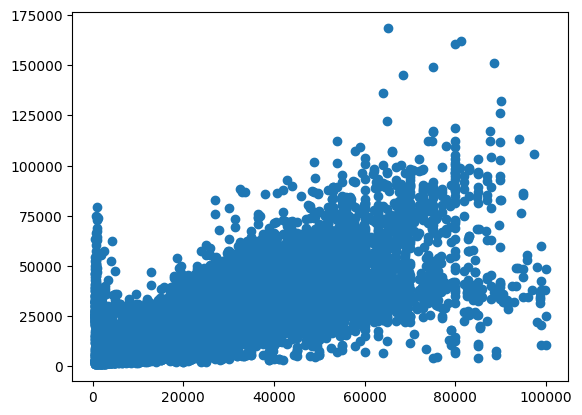

In [488]:
# let's plot how far the predictions are from the real target values (y)
# in the test dataset

# if the values follow a diagonal line (from bottom left to top right)
# => we have good predictions with the model
# we basically compare the predicted values to the actual true values 
# and compare the differences
plt.scatter(y_test, predictions)

In [489]:
# MAE = Mean Absolute Error
mae = metrics.mean_absolute_error(y_test, predictions)
print("MAE: ")
print(f"{round(mae, 2)} $")

# MSE = Mean squared error
mse = metrics.mean_squared_error(y_test, predictions)
print("\nMSE: ")
print(f"{round(mse, 2)} $^2")

# RMSE = Root Mean Square Error
rmse = np.sqrt(mse)
print("\nRMSE: ")
print(f"{round(rmse, 2)} $")

# R-square (or R2) - how well the model describes the original dataset
# 1 => model describes the data perfectly
# 0 => model doesn't describe the data at all
r2 = metrics.r2_score(y_test, predictions)
print("\nR-squared: ")
print(f"{round(r2, 2)}")

MAE: 
4667.6 $

MSE: 
58097387.99 $^2

RMSE: 
7622.16 $

R-squared: 
0.7


C:\Users\pablo\AppData\Local\Temp\ipykernel_34044\2033131320.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot((y_test - predictions))


<Axes: xlabel='price', ylabel='Density'>

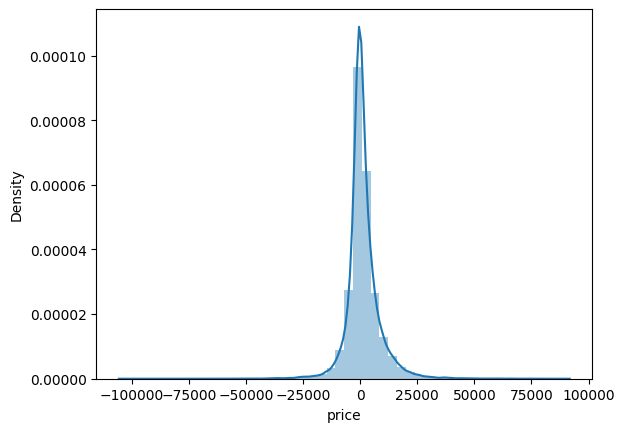

In [490]:
# if the prediction distribution is far from standard normal distribution
# then the model is not probably good enough (should reflect the metrics above)

# distplot is deprecated and will be removed in future seaborn versions
# but no direct replacement has been created so far
sns.distplot((y_test - predictions))

### STEP 6: Testing/using the model in practice (inference)

In [491]:
X.columns

Index(['year', 'condition', 'cylinders', 'odometer', 'clean_title',
       'condition_unknown', 'cylinders_unknown', 'transmission_automatic',
       'transmission_manual', 'transmission_other',
       ...
       'state_sd', 'state_tn', 'state_tx', 'state_ut', 'state_va', 'state_vt',
       'state_wa', 'state_wi', 'state_wv', 'state_wy'],
      dtype='object', length=138)

In [492]:
df.head(3)

,price,year,condition,cylinders,odometer,clean_title,condition_unknown,cylinders_unknown,transmission_automatic,transmission_manual,...,state_sd,state_tn,state_tx,state_ut,state_va,state_vt,state_wa,state_wi,state_wv,state_wy
27,33590,2014.0,2.0,8.0,57923.0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
28,22590,2010.0,2.0,8.0,71229.0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
29,39590,2020.0,2.0,8.0,19160.0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [494]:
# usually for the GUI application, we save the model-object / variable 
# into a file (by using joblib-module)
# and in the GUI application => we load the save model from the file
# and use the model just like here below

# let's create a Python -dictionary, containing our test values
# THE VARIABLE NAMES HAVE TO MATCH WITH THE COLUMNS OF X
# one-hot columns: put 1 in the category the car has
tester_row = {
    'year': 2015,
    'odometer': 90000,               # miles
    'condition': 3,                  # 0 salvage, 1 fair, 2 good, 3 excellent, 4 like new, 5 new
    'cylinders': 6,
    'clean_title': 1,                # 1 = clean title
    'condition_unknown': 0,
    'cylinders_unknown': 0,
    'manufacturer_ford': 1,
    'type_pickup': 1,
    'fuel_gas': 1,
    'transmission_automatic': 1,
    'drive_4wd': 1,
    'paint_color_white': 1,
    'state_tx': 1
}

# convert to pandas format
tester_row = pd.DataFrame([tester_row])

# our model has ~130 columns (because of one-hot encoding)
# reindex adds all the missing columns with 0 and puts them in the same order as X
tester_row = tester_row.reindex(columns=X.columns, fill_value=0)

In [499]:
# get the output/result from the model
# based on the user's given new data (above code cell)
result = np.exp(model.predict(tester_row)[0])

print()
print("Predicted/estimated car value based on given variables:")
print(f"$ {round(float(result), 5)}")
print("------------------------------")


Predicted/estimated car value based on given variables:
$ 22416.0815
------------------------------
